In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [89]:
star = pd.read_csv("data/star.csv")

In [90]:
star.rename(
    columns={
        'Temperature (K)': 'Temperature', 
        'Luminosity(L/Lo)': 'Luminosity',
        'Radius(R/Ro)': 'Radius',
        'Absolute magnitude(Mv)': 'AbsoluteMagnitude',
        'Star type': 'StarType',
        'Star color': 'StarColour',
        'Spectral Class': 'SpectralClass'
    }, inplace=True
)

display(star)

/tmp/ipykernel_35231/1592616849.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  star.rename(


,Temperature,Luminosity,Radius,AbsoluteMagnitude,StarType,StarColour,SpectralClass
0,3068,0.002400,0.1700,16.12,0,Red,M
1,3042,0.000500,0.1542,16.60,0,Red,M
2,2600,0.000300,0.1020,18.70,0,Red,M
3,2800,0.000200,0.1600,16.65,0,Red,M
4,1939,0.000138,0.1030,20.06,0,Red,M
...,...,...,...,...,...,...,...
235,38940,374830.000000,1356.0000,-9.93,5,Blue,O
236,30839,834042.000000,1194.0000,-10.63,5,Blue,O
237,8829,537493.000000,1423.0000,-10.73,5,White,A
238,9235,404940.000000,1112.0000,-11.23,5,White,A


In [91]:
# star['StarType'] = star['StarType'].astype('category')
star['StarColour'] = star['StarColour'].astype('category')

In [92]:
colour_dict = {
    'Red': ['Red'],
    'Blue-white': ['Blue-white', 'Blue White', 'Blue white', 'Blue white', 'Blue-White'], 
    'White': ['white', 'Whitish'],
    'Yellow-white': ['Yellowish White', 'yellow-white', 'White-Yellow'],
    'Yellow-orange': ['Pale yellow orange'],
    'Blue': ['Blue', 'Blue '],
    'Orange': ['Orange'],
    'Yellow': ['Yellowish', 'yellowish'],
    'Orange-red': ['Orange-red']
}

colour_map = {v: k for k, vv in colour_dict.items() for v in vv}

star['StarColour'] = (
    star['StarColour'].map(colour_map)
    .astype(pd.CategoricalDtype(categories=sorted(set(colour_map.values()))))
)

In [93]:
colour_order = [
    "Blue",
    "Blue-white",
    "White",
    "Yellow-white",
    "Yellow",
    "Yellow-orange",
    "Orange",
    "Orange-red",
    "Red"
]

star["StarColour"] = star["StarColour"].astype(
    pd.CategoricalDtype(categories=colour_order, ordered=True)
)

spectral_order = ["O", "B", "A", "F", "G", "K", "M"]

star["SpectralClass"] = star["SpectralClass"].astype(
    pd.CategoricalDtype(categories=spectral_order, ordered=True)
)


In [94]:
star.groupby('StarType')['StarType'].count()

StarType
0    40
1    40
2    40
3    40
4    40
5    40
Name: StarType, dtype: int64

In [95]:
star.groupby('StarColour')['StarColour'].count()

StarColour
Blue              56
Blue-white        40
White              5
Yellow-white      12
Yellow             3
Yellow-orange      1
Orange             2
Red              112
Name: StarColour, dtype: int64

In [96]:
star.groupby('SpectralClass')['SpectralClass'].count()

SpectralClass
O     40
B     46
A     19
F     17
G      1
K      6
M    111
Name: SpectralClass, dtype: int64

array([[<Axes: title={'center': 'Temperature'}>,
        <Axes: title={'center': 'Luminosity'}>],
       [<Axes: title={'center': 'Radius'}>,
        <Axes: title={'center': 'AbsoluteMagnitude'}>],
       [<Axes: title={'center': 'StarType'}>, <Axes: >]], dtype=object)

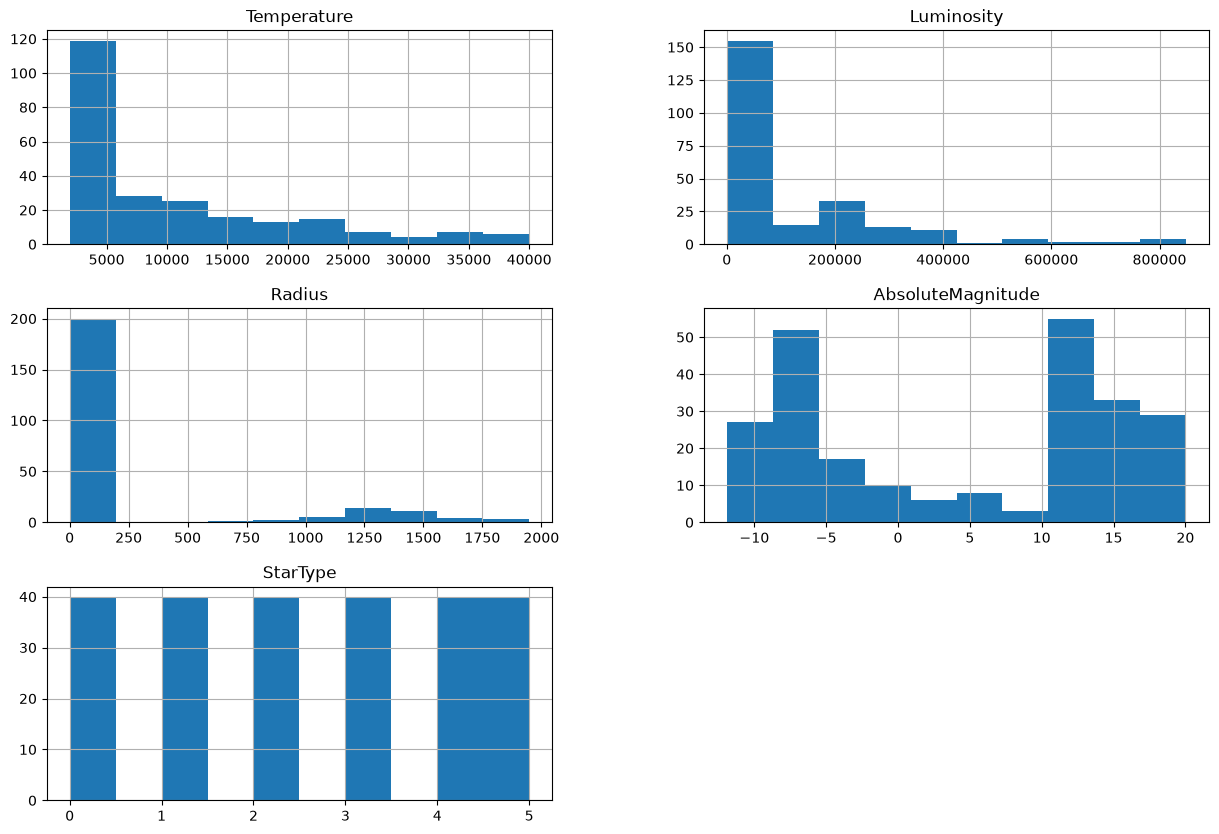

In [97]:
star.hist(figsize = (15,10))

<Axes: xlabel='StarType', ylabel='Temperature'>

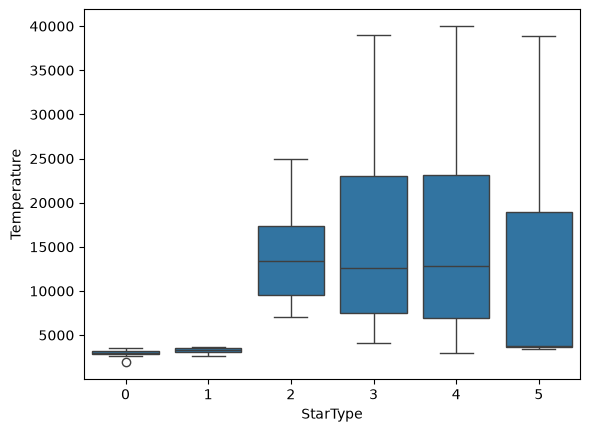

In [98]:
sns.boxplot(data=star, x='StarType', y='Temperature')

<Axes: xlabel='StarType', ylabel='Luminosity'>

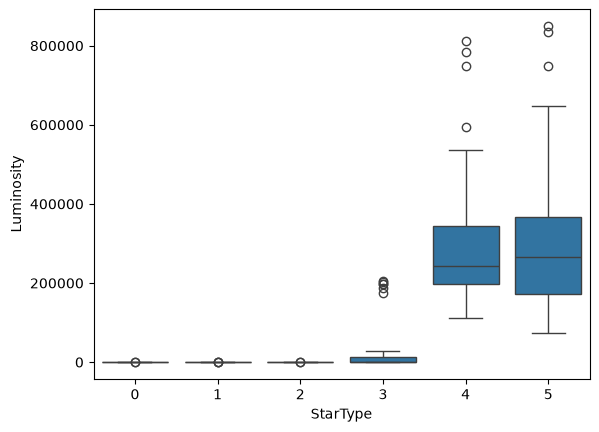

In [99]:
sns.boxplot(data=star, x='StarType', y='Luminosity')

<Axes: xlabel='StarType', ylabel='Radius'>

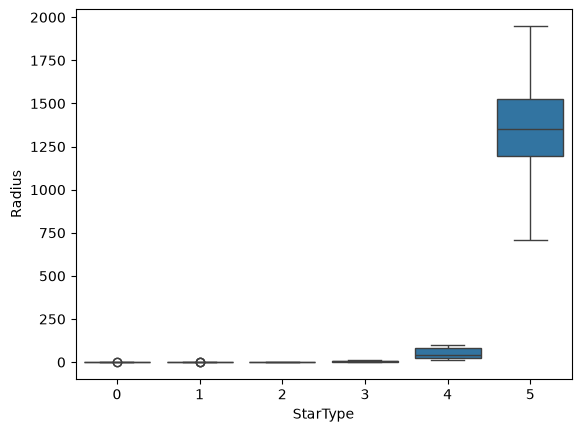

In [100]:
sns.boxplot(data=star, x='StarType', y='Radius')

<Axes: xlabel='StarType', ylabel='AbsoluteMagnitude'>

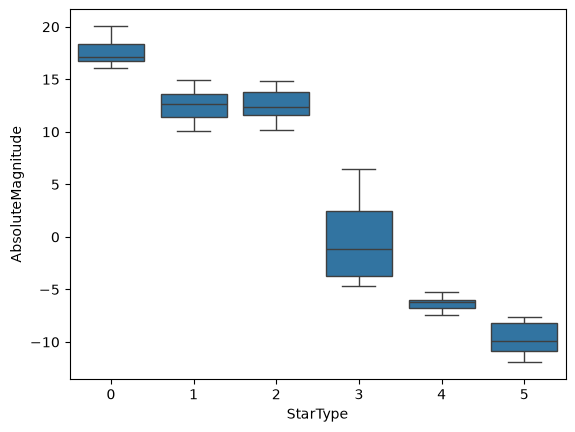

In [101]:
sns.boxplot(data=star, x='StarType', y='AbsoluteMagnitude')

In [102]:
agg_spectral = star.groupby(['StarType', 'SpectralClass'])['StarType'].count().unstack().fillna(0)
agg_spectral

SpectralClass,O,B,A,F,G,K,M
StarType,,,,,,,
0,0.0,0.0,0.0,0.0,0.0,0.0,40.0
1,0.0,0.0,0.0,0.0,0.0,0.0,40.0
2,0.0,24.0,7.0,9.0,0.0,0.0,0.0
3,5.0,13.0,10.0,8.0,0.0,4.0,0.0
4,29.0,2.0,0.0,0.0,0.0,0.0,9.0
5,6.0,7.0,2.0,0.0,1.0,2.0,22.0


<Axes: xlabel='StarType', ylabel='Proportion'>

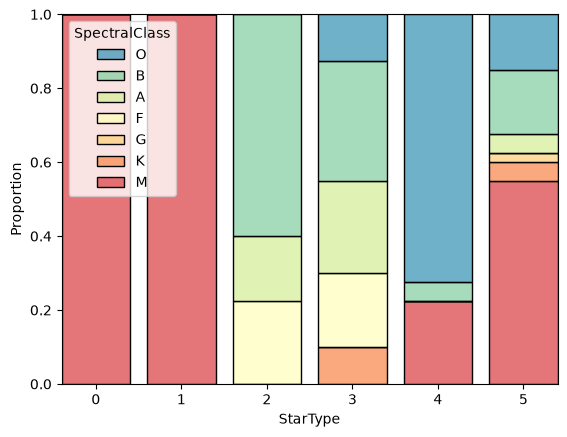

In [103]:
colour_spectral = sns.color_palette("Spectral_r", n_colors=7)

sns.histplot(
    data=star,
    x="StarType", 
    hue="SpectralClass",
    palette= colour_spectral,
    multiple="fill", 
    stat="proportion",
    discrete=True, 
    shrink=.8
)

<Axes: xlabel='StarType', ylabel='Proportion'>

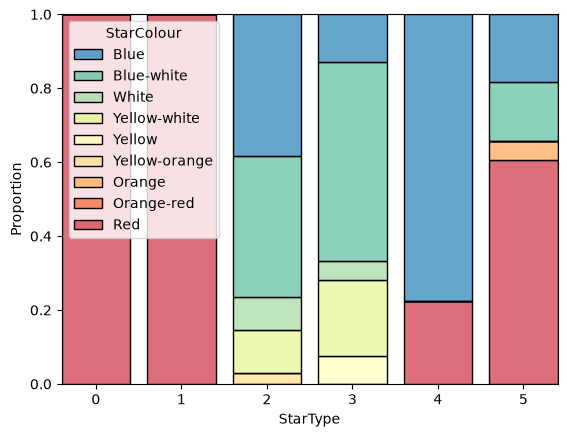

In [104]:
colour_colour = sns.color_palette("Spectral_r", n_colors=9)

sns.histplot(
    data=star,
    x="StarType",
    hue="StarColour",
    palette= colour_colour,
    multiple="fill", 
    stat="proportion",
    discrete=True, 
    shrink=.8
)

<Axes: xlabel='SpectralClass', ylabel='Proportion'>

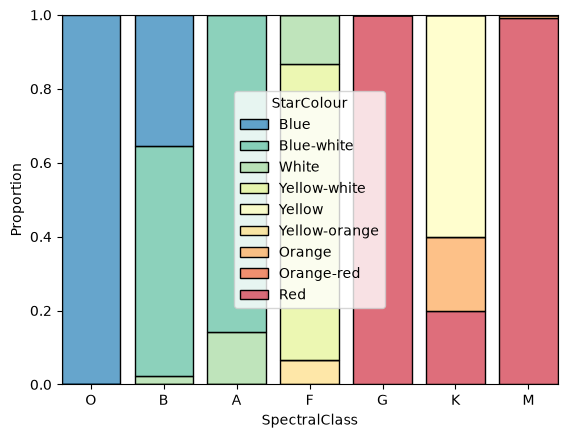

In [105]:
sns.histplot(
    data=star,
    x="SpectralClass",
    hue="StarColour",
    palette= colour_colour,
    multiple="fill", 
    stat="proportion",
    discrete=True, 
    shrink=.8
)

<Axes: xlabel='StarColour', ylabel='Proportion'>

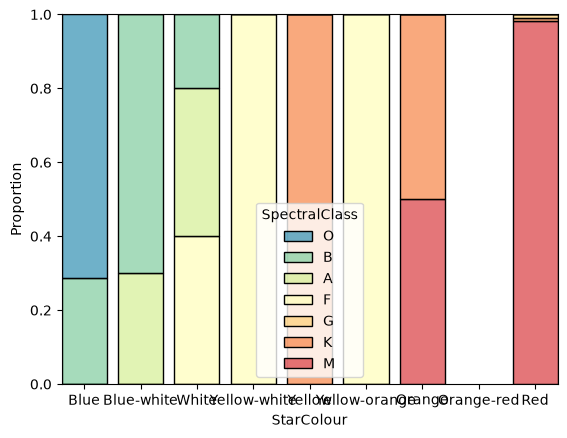

In [106]:
sns.histplot(
    data=star,
    x="StarColour",
    hue="SpectralClass",
    palette= colour_spectral,
    multiple="fill", 
    stat="proportion",
    discrete=True, 
    shrink=.8
)

In [107]:
# colour = ['#0095FF', '#8AC8E3', '#F4740B', '#F4320B', '#F40B0B', 'white', 'yellow', '#FFC30D', '#FFF75C']

# sns.histplot(
#     data=star,
#     x="StarType", 
#     hue="StarColour",
#     palette=colour,
#     multiple="fill", 
#     stat="proportion",
#     discrete=True, 
#     shrink=.8
# )



In [108]:
# colour = ['#0095FF', '#8AC8E3', '#F4740B', '#F4320B', '#F40B0B', 'white', 'yellow', '#FFC30D', '#FFF75C']

# sns.histplot(
#     data=star,
#     x="StarType", 
#     hue="StarColour",
#     palette=colour,
#     multiple="stack", 
#     stat="proportion",
#     discrete=True, 
#     shrink=.8
# )

In [109]:
star.groupby('StarColour').count()

,Temperature,Luminosity,Radius,AbsoluteMagnitude,StarType,SpectralClass
StarColour,,,,,,
Blue,56,56,56,56,56,56
Blue-white,40,40,40,40,40,40
White,5,5,5,5,5,5
Yellow-white,12,12,12,12,12,12
Yellow,3,3,3,3,3,3
Yellow-orange,1,1,1,1,1,1
Orange,2,2,2,2,2,2
Red,112,112,112,112,112,112


In [110]:
star.dtypes

Temperature             int64
Luminosity            float64
Radius                float64
AbsoluteMagnitude     float64
StarType                int64
StarColour           category
SpectralClass        category
dtype: object

# Models

In [159]:
y = star['SpectralClass']
X = star.copy()
del X['StarType']
del X['StarColour']
del X['SpectralClass']
X

,Temperature,Luminosity,Radius,AbsoluteMagnitude
0,3068,0.002400,0.1700,16.12
1,3042,0.000500,0.1542,16.60
2,2600,0.000300,0.1020,18.70
3,2800,0.000200,0.1600,16.65
4,1939,0.000138,0.1030,20.06
...,...,...,...,...
235,38940,374830.000000,1356.0000,-9.93
236,30839,834042.000000,1194.0000,-10.63
237,8829,537493.000000,1423.0000,-10.73
238,9235,404940.000000,1112.0000,-11.23


In [160]:
# Train/test split
data_train, data_test, target_train, target_test = train_test_split(
    X, y, random_state=42,test_size=0.25
)


In [161]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate

In [162]:
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import make_column_transformer
from sklearn.compose import make_column_selector as selector

numerical_columns_selector = selector(dtype_exclude=["object", "string", "category"])
categorical_columns_selector = selector(dtype_include=["object", "string", "category"])

numerical_columns = numerical_columns_selector(X)
categorical_columns = categorical_columns_selector(X)

categorical_preprocessor = OrdinalEncoder(
    handle_unknown="use_encoded_value", unknown_value=-1
)
preprocessor = make_column_transformer(
    (categorical_preprocessor, categorical_columns),
    remainder="passthrough",
)

In [163]:
model = make_pipeline(preprocessor, DecisionTreeClassifier())
model

_ = model.fit(data_train, target_train)

In [164]:
cv_results = cross_validate(model, X, y)
scores = cv_results["test_score"]
print(f"The accuracy is: {scores.mean():.3f} ± {scores.std():.3f}")

The accuracy is: 0.875 ± 0.062


/opt/python/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


In [165]:
y_pred = model.predict(data_test)

In [166]:
from sklearn.metrics import confusion_matrix

confusion_matrix(target_test, y_pred)

array([[ 0,  1,  0,  1,  0,  0,  0],
       [ 0, 12,  0,  0,  0,  0,  1],
       [ 1,  0,  2,  0,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  2,  1,  0,  0,  0],
       [ 0,  0,  0,  0,  0, 28,  0],
       [ 1,  2,  0,  0,  0,  0,  8]])

In [167]:
tree = DecisionTreeClassifier()
encoder = OneHotEncoder(handle_unknown="ignore")
model = tree.fit(data_train, target_train)

accuracy = model.score(data_test, target_test)

# Confusion matrix from another project